# Assignment 2 - Hand Gesture Recognition: A1 baselines vs MobileNetV4
**Aiya Zhakupova** · Astana IT University · Computer Vision

Classes: `1` (one finger), `2` (two fingers), `3` (three fingers).

All models are trained on the same training split and evaluated on the same test set:
1. **Logistic Regression** on raw pixels (A1 baseline)
2. **CNN from scratch** (A1 baseline, same architecture)
3. **MobileNetV4** (Google, 2024) pretrained on ImageNet and fine-tuned on our gestures (SOTA model)

Extra experiments: training curves, robustness under different conditions, latency, ablation
(with/without augmentation, with/without pretraining) and Grad-CAM explanations.
The best model is exported for the web app.

In [1]:
import sys, os, subprocess

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)

# Folder that contains dataset/train/{1,2,3} and dataset/validation/{1,2,3}
DATA_DIR = '/content/drive/MyDrive/asik2/dataset' if IN_COLAB else os.environ.get('A2_DATA', 'dataset')
OUT_DIR = '/content/drive/MyDrive/asik2/outputs' if IN_COLAB else os.environ.get('A2_OUT', 'outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# QUICK=1 runs a tiny version of everything (used only to smoke-test the notebook)
QUICK = os.environ.get('A2_QUICK') == '1'

Mounted at /content/drive


In [2]:
import hashlib, time, copy, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageEnhance, ImageFilter
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# TensorFlow grabs all GPU memory by default, which would leave nothing for PyTorch
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import timm

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("PyTorch device:", DEVICE, "| TF GPUs:", tf.config.list_physical_devices('GPU'))

CLASS_NAMES = ['1', '2', '3']
CLASS_LABELS = ['One finger', 'Two fingers', 'Three fingers']

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches='tight')

PyTorch device: cuda | TF GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset update
A1 used 300 images (100 per class). The dataset is now expanded to 800 images per class in `train`
plus 100 per class in `validation`. Some files were saved twice (e.g. `1000.jpg` and `1000(1).jpg`),
so exact duplicates are removed by MD5 hash before splitting, otherwise the same picture could end up
in both training and test data.

In [4]:
import glob

# Automatically look for the dataset path if the default one is not found
if not os.path.exists(os.path.join(DATA_DIR, 'train', '1')):
    print(f"Warning: Default path {DATA_DIR} not found. Searching in Google Drive...")
    potential_paths = glob.glob('/content/drive/MyDrive/**/dataset', recursive=True)
    if potential_paths:
        DATA_DIR = potential_paths[0]
        print(f"Found dataset at: {DATA_DIR}")
    else:
        print("Could not find a 'dataset' folder in Drive. Please verify your Google Drive folder structure.")

def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def scan(split):
    rows = []
    for label, c in enumerate(CLASS_NAMES):
        folder = os.path.join(DATA_DIR, split, c)
        if not os.path.exists(folder):
            print(f"Error: Directory not found: {folder}")
            continue
        for fname in sorted(os.listdir(folder)):
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                path = os.path.join(folder, fname)
                rows.append({'path': path, 'label': label, 'folder': split, 'md5': md5(path)})
    return pd.DataFrame(rows)

try:
    df_raw = pd.concat([scan('train'), scan('validation')], ignore_index=True)
    if len(df_raw) > 0:
        df = df_raw.drop_duplicates('md5', keep='first').reset_index(drop=True)
        print(f"Images found: {len(df_raw)} | exact duplicates removed: {len(df_raw) - len(df)} | unique: {len(df)}")
    else:
        print("No images found. Please check your dataset folder configuration.")
except Exception as e:
    print("An error occurred while scanning:", e)

Found dataset at: /content/drive/MyDrive/dataset
Images found: 2700 | exact duplicates removed: 43 | unique: 2657


In [5]:
# Test set = the `validation` folder (never used for training or model selection).
# The `train` folder is split 85/15 into train / validation (validation is used for early stopping).
test_df = df[df.folder == 'validation'].reset_index(drop=True)
train_full = df[df.folder == 'train']
train_df, val_df = train_test_split(train_full, test_size=0.15, stratify=train_full.label, random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

if QUICK:
    train_df = train_df.groupby('label').head(50).reset_index(drop=True)
    val_df = val_df.groupby('label').head(15).reset_index(drop=True)
    test_df = test_df.groupby('label').head(20).reset_index(drop=True)

split_table = pd.DataFrame({
    name: part.label.map(dict(enumerate(CLASS_NAMES))).value_counts().sort_index()
    for name, part in [('train', train_df), ('validation', val_df), ('test', test_df)]
})
split_table.loc['TOTAL'] = split_table.sum()
print(split_table)
split_table.to_csv(os.path.join(OUT_DIR, 'split_counts.csv'))
pd.concat([train_df.assign(split='train'), val_df.assign(split='validation'), test_df.assign(split='test')]) \
    .drop(columns='md5').to_csv(os.path.join(OUT_DIR, 'splits.csv'), index=False)

       train  validation  test
label                         
1        647         115    95
2        680         120   100
3        680         120   100
TOTAL   2007         355   295


In [6]:
# Every image is loaded once and cached at 224x224 (Google Drive reads are slow).
# Logistic Regression and the CNN get a 128x128 version, like in A1.
IMG_SIZE = 224
A1_SIZE = (128, 128)

def load_pil(path):
    return Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

t0 = time.time()
train_pils = [load_pil(p) for p in train_df.path]
val_pils = [load_pil(p) for p in val_df.path]
test_pils = [load_pil(p) for p in test_df.path]
y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values
print(f"Loaded {len(train_pils) + len(val_pils) + len(test_pils)} images in {time.time() - t0:.1f}s")

Loaded 2657 images in 9.7s


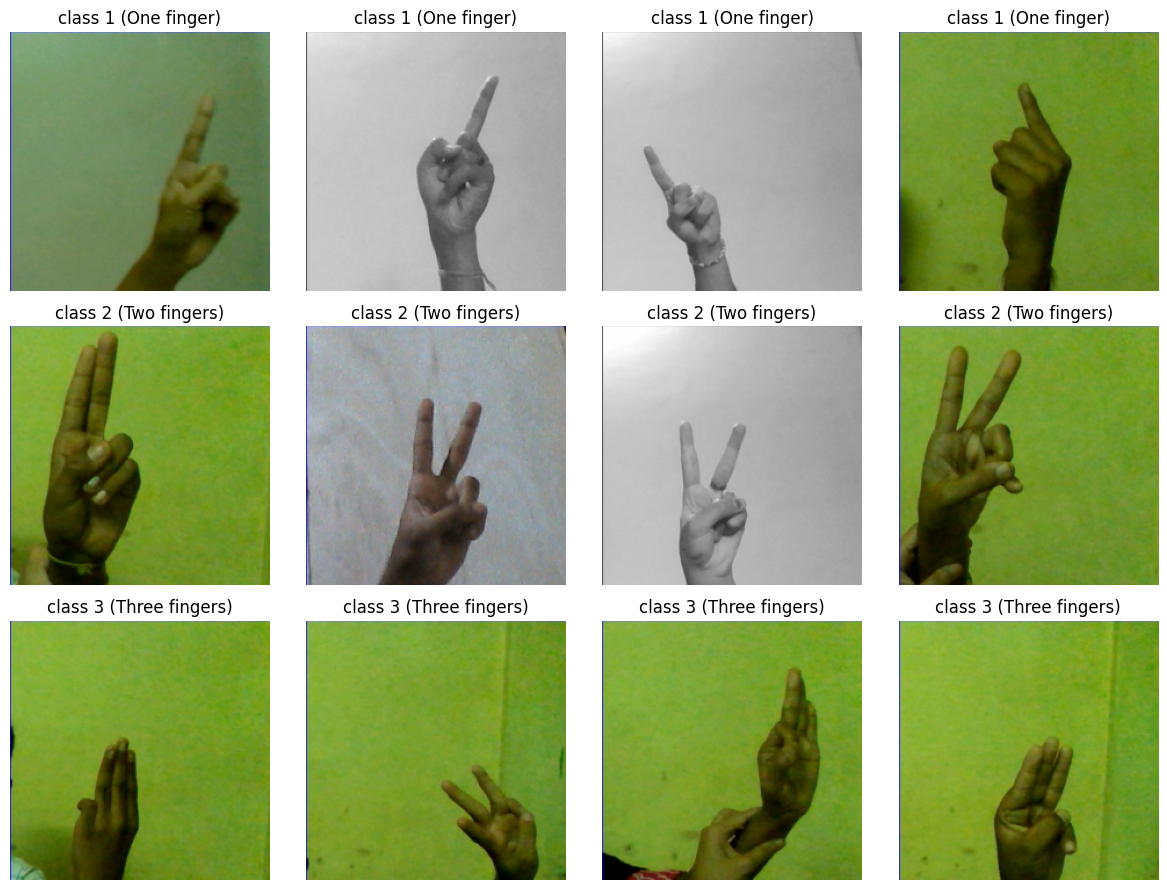

In [7]:
fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(12, 3 * len(CLASS_NAMES)))
for row in range(len(CLASS_NAMES)):
    idx = np.where(y_train == row)[0][:4]
    for col, i in enumerate(idx):
        axes[row, col].imshow(train_pils[i])
        axes[row, col].set_title(f"class {CLASS_NAMES[row]} ({CLASS_LABELS[row]})")
        axes[row, col].axis('off')
plt.tight_layout(); savefig('samples.png'); plt.show()

In [8]:
def to_array128(pils):
    return np.stack([np.array(p.resize(A1_SIZE, Image.BILINEAR)) for p in pils]).astype('float32')

X_train128, X_val128 = to_array128(train_pils), to_array128(val_pils)
print("A1-style arrays:", X_train128.shape, X_val128.shape)

A1-style arrays: (2007, 128, 128, 3) (355, 128, 128, 3)


## 2. Model 1 - Logistic Regression (A1 baseline)
Same as A1: raw pixels (128×128×3 = 49 152 features), scaled to [0, 1].

In [9]:
lr_model = LogisticRegression(max_iter=200 if QUICK else 2000, random_state=SEED)
t0 = time.time()
lr_model.fit(X_train128.reshape(len(X_train128), -1) / 255.0, y_train)
lr_train_time = time.time() - t0
print(f"Logistic Regression trained in {lr_train_time:.1f}s")

Logistic Regression trained in 491.4s


## 3. Model 2 - CNN from scratch (A1 baseline)
Same architecture, augmentation and training settings as in A1. The only change is more training data.

In [10]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),        # mirror the image left-right
    layers.RandomRotation(0.08),            # rotate up to ~ +/-29 degrees (0.08 * 360)
    layers.RandomZoom(0.15),                # zoom in/out up to 15%
    layers.RandomContrast(0.15),            # vary contrast, simulates different lighting
    layers.RandomTranslation(0.1, 0.1),     # shift the image slightly, simulates hand not centered
], name="data_augmentation")

cnn_model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(CLASS_NAMES), activation='softmax')
], name="cnn_from_scratch")

cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.summary()

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072,419 (4.09 MB)

 Trainable params: 1,072,419 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
CNN_EPOCHS = 2 if QUICK else 25
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

t0 = time.time()
history_cnn = cnn_model.fit(
    X_train128, y_train,
    validation_data=(X_val128, y_val),
    batch_size=10,
    epochs=CNN_EPOCHS,
    callbacks=[early_stop],
    verbose=2
)
cnn_train_time = time.time() - t0
print(f"CNN trained in {cnn_train_time:.1f}s")

Epoch 1/25
201/201 - 10s - 50ms/step - accuracy: 0.3293 - loss: 1.1022 - val_accuracy: 0.3380 - val_loss: 1.0985
Epoch 2/25
201/201 - 2s - 10ms/step - accuracy: 0.3378 - loss: 1.1003 - val_accuracy: 0.3380 - val_loss: 1.0984
Epoch 3/25
201/201 - 2s - 10ms/step - accuracy: 0.3209 - loss: 1.0994 - val_accuracy: 0.3408 - val_loss: 1.0984
Epoch 4/25
201/201 - 2s - 10ms/step - accuracy: 0.3533 - loss: 1.0980 - val_accuracy: 0.3493 - val_loss: 1.0990
Epoch 5/25
201/201 - 2s - 10ms/step - accuracy: 0.3453 - loss: 1.0952 - val_accuracy: 0.3662 - val_loss: 1.0820
Epoch 6/25
201/201 - 3s - 13ms/step - accuracy: 0.3582 - loss: 1.0872 - val_accuracy: 0.3352 - val_loss: 1.0943
Epoch 7/25
201/201 - 2s - 10ms/step - accuracy: 0.3732 - loss: 1.0800 - val_accuracy: 0.3521 - val_loss: 1.0759
Epoch 8/25
201/201 - 2s - 10ms/step - accuracy: 0.3866 - loss: 1.0795 - val_accuracy: 0.3606 - val_loss: 1.0824
Epoch 9/25
201/201 - 2s - 10ms/step - accuracy: 0.3976 - loss: 1.0743 - val_accuracy: 0.3493 - val_loss

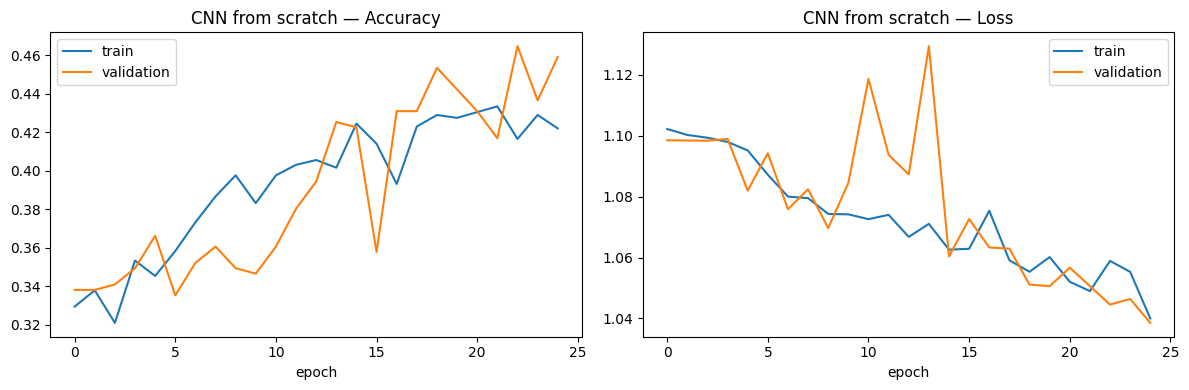

In [12]:
def plot_history(hist, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist['accuracy'], label='train')
    axes[0].plot(hist['val_accuracy'], label='validation')
    axes[0].set_title(f'{title} - Accuracy')
    axes[0].set_xlabel('epoch'); axes[0].legend()

    axes[1].plot(hist['loss'], label='train')
    axes[1].plot(hist['val_loss'], label='validation')
    axes[1].set_title(f'{title} - Loss')
    axes[1].set_xlabel('epoch'); axes[1].legend()
    plt.tight_layout(); savefig(fname); plt.show()

plot_history(history_cnn.history, "CNN from scratch", 'curves_cnn.png')

## 4. Model 3 - MobileNetV4 (SOTA)
**MobileNetV4** (Qin et al., Google, 2024, *"MobileNetV4 - Universal Models for the Mobile Ecosystem"*)
is the latest MobileNet generation. It introduces the **Universal Inverted Bottleneck (UIB)** block,
which unifies the inverted bottleneck, ConvNeXt-style and FFN blocks, and was found with neural
architecture search to be Pareto-optimal (accuracy vs latency) across CPUs, GPUs, DSPs and mobile
accelerators. We use `mobilenetv4_conv_small` from `timm`, pretrained on ImageNet-1k, replace the
1000-class head with a 3-class head and fine-tune the whole network.

model.safetensors: reconstructing file:   0%|          |  0.00B / 15.2MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch  1/15  loss 3.0942  acc 0.479  val_loss 0.8068  val_acc 0.704
epoch  2/15  loss 0.8788  acc 0.658  val_loss 0.6270  val_acc 0.811
epoch  3/15  loss 0.7109  acc 0.758  val_loss 0.4752  val_acc 0.921
epoch  4/15  loss 0.6087  acc 0.834  val_loss 0.4209  val_acc 0.941
epoch  5/15  loss 0.5466  acc 0.871  val_loss 0.3798  val_acc 0.980
epoch  6/15  loss 0.4971  acc 0.899  val_loss 0.3655  val_acc 0.983
epoch  7/15  loss 0.4545  acc 0.927  val_loss 0.3519  val_acc 0.989
epoch  8/15  loss 0.4396  acc 0.936  val_loss 0.3460  val_acc 0.989
epoch  9/15  loss 0.4344  acc 0.942  val_loss 0.3333  val_acc 0.992
epoch 10/15  loss 0.4263  acc 0.941  val_loss 0.3320  val_acc 0.992
epoch 11/15  loss 0.3946  acc 0.959  val_loss 0.3267  val_acc 0.986
epoch 12/15  loss 0.3909  acc 0.959  val_loss 0.3263  val_acc 0.989
epoch 13/15  loss 0.3926  acc 0.958  val_loss 0.3260  val_acc 0.989
epoch 14/15  loss 0.3783  acc 0.966  val_loss 0.3235  val_acc 0.989
epoch 15/15  loss 0.3870  acc 0.959  val_loss 0.

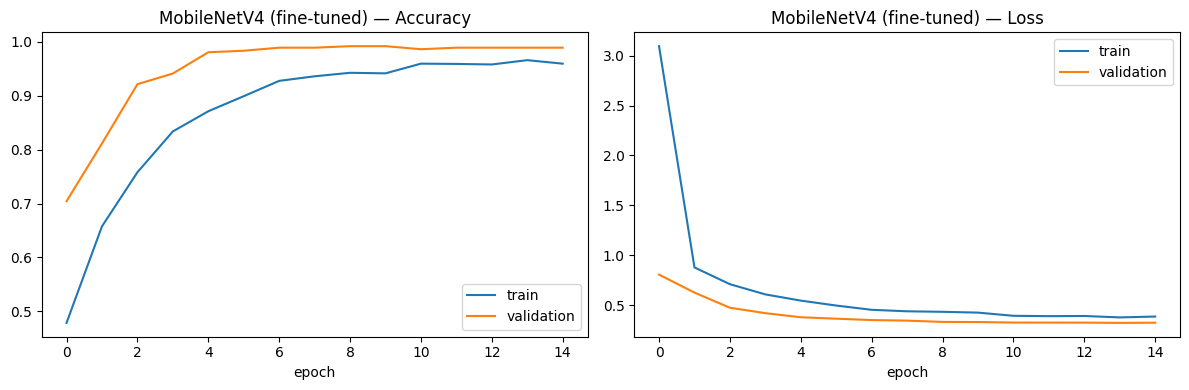

In [13]:
MNV4_NAME = 'mobilenetv4_conv_small.e2400_r224_in1k'
MNV4_EPOCHS = 1 if QUICK else 15
BATCH_SIZE = 32

_cfg = timm.create_model(MNV4_NAME, pretrained=False).pretrained_cfg
MEAN, STD = _cfg['mean'], _cfg['std']

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

class GestureDataset(Dataset):
    def __init__(self, pils, labels, transform):
        self.pils, self.labels, self.transform = pils, labels, transform
    def __len__(self):
        return len(self.pils)
    def __getitem__(self, i):
        return self.transform(self.pils[i]), int(self.labels[i])

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

def train_mnv4(augment=True, pretrained=True, epochs=MNV4_EPOCHS):
    torch.manual_seed(SEED)
    model = timm.create_model(MNV4_NAME, pretrained=pretrained, num_classes=len(CLASS_NAMES)).to(DEVICE)
    train_loader = DataLoader(GestureDataset(train_pils, y_train, train_tf if augment else eval_tf),
                              batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(GestureDataset(val_pils, y_val, eval_tf), batch_size=64)

    # a pretrained network only needs small updates; a random one needs a larger learning rate
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4 if pretrained else 2e-3, weight_decay=0.05)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    hist = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_acc, best_state = -1.0, None
    t0 = time.time()
    for epoch in range(epochs):
        loss, acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        scheduler.step()
        for k, v in zip(hist, [loss, acc, val_loss, val_acc]):
            hist[k].append(v)
        if val_acc > best_acc:
            best_acc, best_state = val_acc, copy.deepcopy(model.state_dict())
        print(f"epoch {epoch + 1:2d}/{epochs}  loss {loss:.4f}  acc {acc:.3f}  val_loss {val_loss:.4f}  val_acc {val_acc:.3f}")
    model.load_state_dict(best_state)  # keep the epoch with the best validation accuracy
    model.eval()
    return model, hist, time.time() - t0

mnv4_model, history_mnv4, mnv4_train_time = train_mnv4()
print(f"MobileNetV4 trained in {mnv4_train_time:.1f}s on {DEVICE}")
plot_history(history_mnv4, "MobileNetV4 (fine-tuned)", 'curves_mobilenetv4.png')

## 5. Comparison on the test set

=== Logistic Regression (A1) ===
              precision    recall  f1-score   support

           1       0.41      0.31      0.35        95
           2       0.26      0.19      0.22       100
           3       0.41      0.62      0.49       100

    accuracy                           0.37       295
   macro avg       0.36      0.37      0.35       295
weighted avg       0.36      0.37      0.35       295

=== CNN from scratch (A1) ===
              precision    recall  f1-score   support

           1       0.51      0.33      0.40        95
           2       0.44      0.27      0.33       100
           3       0.38      0.66      0.49       100

    accuracy                           0.42       295
   macro avg       0.44      0.42      0.41       295
weighted avg       0.44      0.42      0.41       295

=== MobileNetV4 (SOTA) ===
              precision    recall  f1-score   support

           1       0.99      0.99      0.99        95
           2       0.99      0.97      

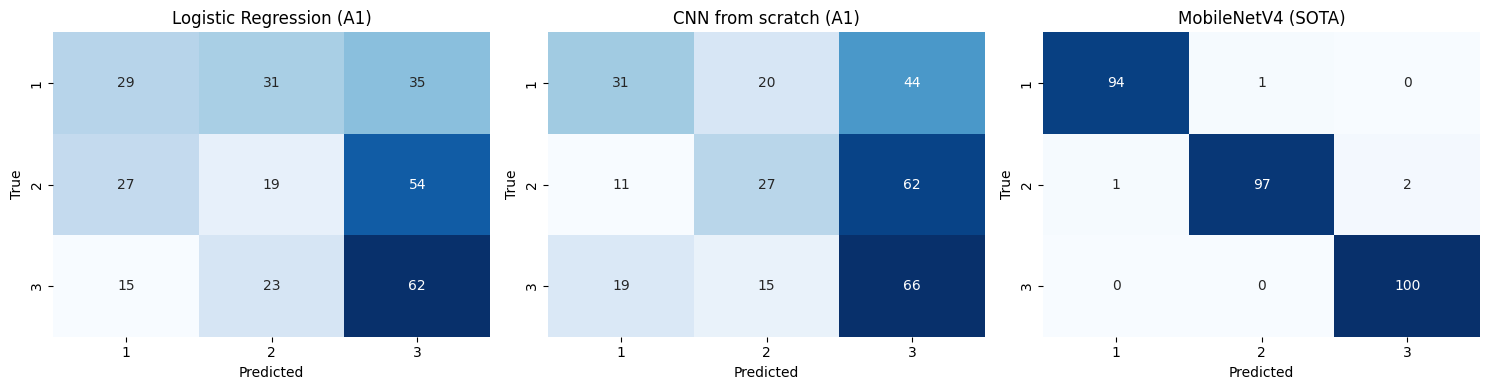

In [14]:
def predict_lr(pils):
    X = to_array128(pils)
    return lr_model.predict_proba(X.reshape(len(X), -1) / 255.0)

def predict_cnn(pils):
    return cnn_model.predict(to_array128(pils), verbose=0)

@torch.no_grad()
def predict_mnv4(pils, model=None):
    model = model or mnv4_model
    model.eval()
    probs = []
    for i in range(0, len(pils), 64):
        x = torch.stack([eval_tf(p) for p in pils[i:i + 64]]).to(DEVICE)
        probs.append(F.softmax(model(x), dim=1).cpu().numpy())
    return np.concatenate(probs)

PREDICTORS = {
    'Logistic Regression (A1)': predict_lr,
    'CNN from scratch (A1)': predict_cnn,
    'MobileNetV4 (SOTA)': predict_mnv4,
}

def metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision (macro)': p, 'Recall (macro)': r, 'F1 (macro)': f1}

def plot_confusion(y_true, y_pred, name, ax):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('True')

test_preds = {name: fn(test_pils).argmax(1) for name, fn in PREDICTORS.items()}

fig, axes = plt.subplots(1, len(PREDICTORS), figsize=(5 * len(PREDICTORS), 4))
for ax, (name, y_pred) in zip(axes, test_preds.items()):
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))
    plot_confusion(y_test, y_pred, name, ax)
plt.tight_layout(); savefig('confusion_matrices.png'); plt.show()

### Latency and model size
Inference time is measured on **CPU** with one image at a time (the same setting as the web app),
averaged over repeated runs after a warm-up. Preprocessing is not included.

In [15]:
def time_it(fn, n_runs):
    for _ in range(5):
        fn()
    t0 = time.perf_counter()
    for _ in range(n_runs):
        fn()
    return (time.perf_counter() - t0) / n_runs * 1000

N_RUNS = 10 if QUICK else 100
x128 = to_array128(test_pils[:1])
x_lr = x128.reshape(1, -1) / 255.0
mnv4_cpu = copy.deepcopy(mnv4_model).cpu().eval()
x_t = eval_tf(test_pils[0]).unsqueeze(0)

with tf.device('/CPU:0'):
    cnn_ms = time_it(lambda: cnn_model(x128, training=False), N_RUNS)
with torch.no_grad():
    mnv4_ms = time_it(lambda: mnv4_cpu(x_t), N_RUNS)
latency_ms = {
    'Logistic Regression (A1)': time_it(lambda: lr_model.predict_proba(x_lr), N_RUNS),
    'CNN from scratch (A1)': cnn_ms,
    'MobileNetV4 (SOTA)': mnv4_ms,
}
n_params = {
    'Logistic Regression (A1)': lr_model.coef_.size + lr_model.intercept_.size,
    'CNN from scratch (A1)': cnn_model.count_params(),
    'MobileNetV4 (SOTA)': sum(p.numel() for p in mnv4_model.parameters()),
}
train_time_s = {
    'Logistic Regression (A1)': lr_train_time,
    'CNN from scratch (A1)': cnn_train_time,
    'MobileNetV4 (SOTA)': mnv4_train_time,
}
print("CPU:", platform.processor() or platform.machine(), "| threads:", torch.get_num_threads())

CPU: x86_64 | threads: 1


In [16]:
results = pd.DataFrame([
    {'Model': name, **metrics(y_test, y_pred),
     'CPU latency (ms/img)': latency_ms[name],
     'Params (M)': n_params[name] / 1e6,
     'Train time (s)': train_time_s[name]}
    for name, y_pred in test_preds.items()
]).round(3)
print(results.to_string(index=False))
results.to_csv(os.path.join(OUT_DIR, 'results_test.csv'), index=False)
results

                   Model  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  CPU latency (ms/img)  Params (M)  Train time (s)
Logistic Regression (A1)     0.373              0.360           0.372       0.354                 0.309       0.147         491.420
   CNN from scratch (A1)     0.420              0.442           0.419       0.405                20.815       1.072          59.924
      MobileNetV4 (SOTA)     0.986              0.987           0.986       0.986                14.370       2.497         285.260


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),CPU latency (ms/img),Params (M),Train time (s)
0,Logistic Regression (A1),0.373,0.360,0.372,0.354,0.309,0.147,491.420
1,CNN from scratch (A1),0.420,0.442,0.419,0.405,20.815,1.072,59.924
2,MobileNetV4 (SOTA),0.986,0.987,0.986,0.986,14.370,2.497,285.260


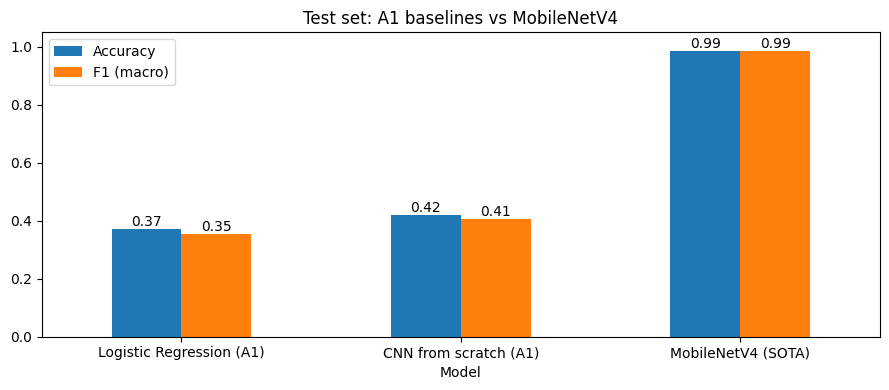

In [17]:
ax = results.set_index('Model')[['Accuracy', 'F1 (macro)']].plot.bar(figsize=(9, 4), rot=0, ylim=(0, 1.05))
ax.set_title('Test set: A1 baselines vs MobileNetV4')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.tight_layout(); savefig('comparison_bar.png'); plt.show()

## 6. Robustness: accuracy under different conditions
All training photos have the same green background and similar light. A webcam in the web app
will see other rooms and lighting, so the test set is re-evaluated under simulated conditions:
low light, over-exposure, motion/defocus blur, sensor noise, rotation and a **new background**
(the green wall is replaced by a random texture with a simple chroma key).

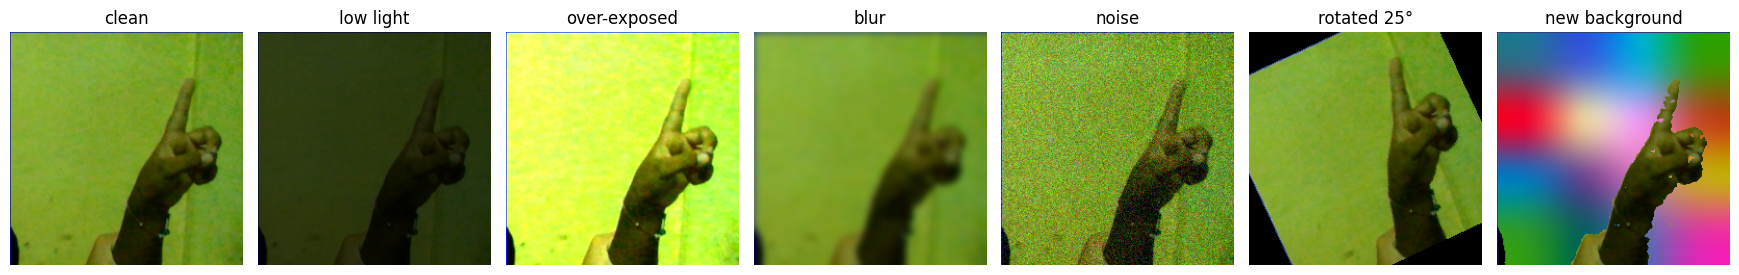

In [18]:
rng = np.random.default_rng(SEED)

def add_noise(img, sigma=25):
    arr = np.array(img).astype('float32') + rng.normal(0, sigma, (IMG_SIZE, IMG_SIZE, 3))
    return Image.fromarray(np.clip(arr, 0, 255).astype('uint8'))

def random_background():
    # smooth random colours, upscaled from a tiny random image
    small = rng.integers(0, 255, (4, 4, 3), dtype=np.uint8)
    return np.array(Image.fromarray(small).resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)).astype('float32')

def new_background(img):
    arr = np.array(img).astype('float32')
    r, g, b = arr[..., 0], arr[..., 1], arr[..., 2]
    green = (g > r + 15) & (g > b + 15)   # the green wall; skin has r > g
    arr[green] = random_background()[green]
    return Image.fromarray(arr.astype('uint8'))

CONDITIONS = {
    'clean': lambda im: im,
    'low light': lambda im: ImageEnhance.Brightness(im).enhance(0.35),
    'over-exposed': lambda im: ImageEnhance.Brightness(im).enhance(1.8),
    'blur': lambda im: im.filter(ImageFilter.GaussianBlur(3)),
    'noise': add_noise,
    'rotated 25°': lambda im: im.rotate(25),
    'new background': new_background,
}

fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(2.5 * len(CONDITIONS), 2.8))
for ax, (cond, fn) in zip(axes, CONDITIONS.items()):
    ax.imshow(fn(test_pils[0])); ax.set_title(cond); ax.axis('off')
plt.tight_layout(); savefig('conditions.png'); plt.show()

                Logistic Regression (A1)  CNN from scratch (A1)  \
clean                              0.373                  0.420   
low light                          0.393                  0.305   
over-exposed                       0.386                  0.363   
blur                               0.420                  0.376   
noise                              0.386                  0.403   
rotated 25°                        0.329                  0.346   
new background                     0.288                  0.383   

                MobileNetV4 (SOTA)  
clean                        0.986  
low light                    0.847  
over-exposed                 0.895  
blur                         0.851  
noise                        0.841  
rotated 25°                  0.973  
new background               0.902  


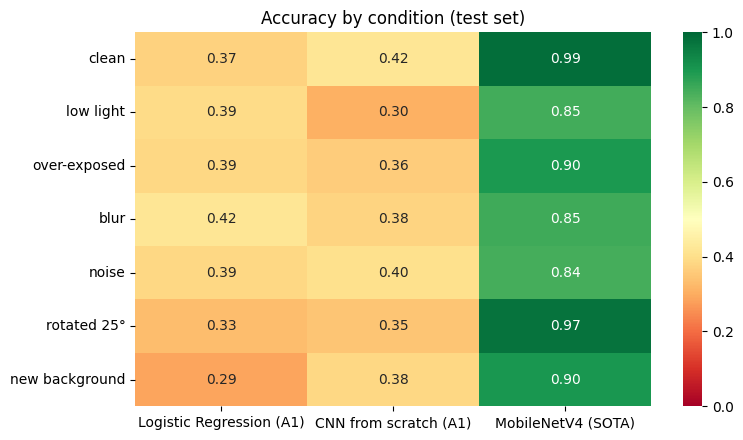

In [19]:
cond_pils = {cond: [fn(p) for p in test_pils] for cond, fn in CONDITIONS.items()}
robustness = pd.DataFrame({
    name: {cond: accuracy_score(y_test, fn(pils).argmax(1)) for cond, pils in cond_pils.items()}
    for name, fn in PREDICTORS.items()
}).round(3)
print(robustness)
robustness.to_csv(os.path.join(OUT_DIR, 'results_robustness.csv'))

plt.figure(figsize=(8, 4.5))
sns.heatmap(robustness, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1)
plt.title('Accuracy by condition (test set)')
plt.tight_layout(); savefig('robustness_heatmap.png'); plt.show()

## 7. Ablation (MobileNetV4)
Two components are removed one at a time to see how much each contributes:
- **no augmentation** - train on the plain images only
- **no pretraining** - same network, random weights instead of ImageNet weights

In [20]:
ablation_models = {'MobileNetV4 full (pretrained + aug)': (mnv4_model, history_mnv4)}
for name, kwargs in [('MobileNetV4 without augmentation', dict(augment=False)),
                     ('MobileNetV4 without pretraining', dict(pretrained=False))]:
    print(f"--- {name} ---")
    model, hist, _ = train_mnv4(**kwargs)
    ablation_models[name] = (model, hist)

ablation = pd.DataFrame([
    {'Variant': name,
     **{k: v for k, v in metrics(y_test, predict_mnv4(test_pils, model).argmax(1)).items()
        if k in ('Accuracy', 'F1 (macro)')},
     'Mean acc. over conditions': np.mean([accuracy_score(y_test, predict_mnv4(p, model).argmax(1))
                                           for p in cond_pils.values()])}
    for name, (model, _) in ablation_models.items()
]).round(3)
print(ablation.to_string(index=False))
ablation.to_csv(os.path.join(OUT_DIR, 'results_ablation.csv'), index=False)
ablation

--- MobileNetV4 without augmentation ---
epoch  1/15  loss 2.3768  acc 0.621  val_loss 0.7116  val_acc 0.800
epoch  2/15  loss 0.5627  acc 0.878  val_loss 0.4421  val_acc 0.938
epoch  3/15  loss 0.4469  acc 0.945  val_loss 0.3866  val_acc 0.969
epoch  4/15  loss 0.3959  acc 0.974  val_loss 0.4113  val_acc 0.963
epoch  5/15  loss 0.3763  acc 0.980  val_loss 0.3646  val_acc 0.980
epoch  6/15  loss 0.3548  acc 0.987  val_loss 0.3540  val_acc 0.977
epoch  7/15  loss 0.3439  acc 0.992  val_loss 0.3506  val_acc 0.989
epoch  8/15  loss 0.3384  acc 0.994  val_loss 0.3460  val_acc 0.989
epoch  9/15  loss 0.3334  acc 0.997  val_loss 0.3399  val_acc 0.989
epoch 10/15  loss 0.3271  acc 0.995  val_loss 0.3394  val_acc 0.983
epoch 11/15  loss 0.3248  acc 0.998  val_loss 0.3343  val_acc 0.989
epoch 12/15  loss 0.3243  acc 0.998  val_loss 0.3328  val_acc 0.989
epoch 13/15  loss 0.3239  acc 0.997  val_loss 0.3314  val_acc 0.992
epoch 14/15  loss 0.3172  acc 0.999  val_loss 0.3331  val_acc 0.989
epoch 1

,Variant,Accuracy,F1 (macro),Mean acc. over conditions
0,MobileNetV4 full (pretrained + aug),0.986,0.986,0.899
1,MobileNetV4 without augmentation,0.976,0.976,0.762
2,MobileNetV4 without pretraining,0.549,0.541,0.440


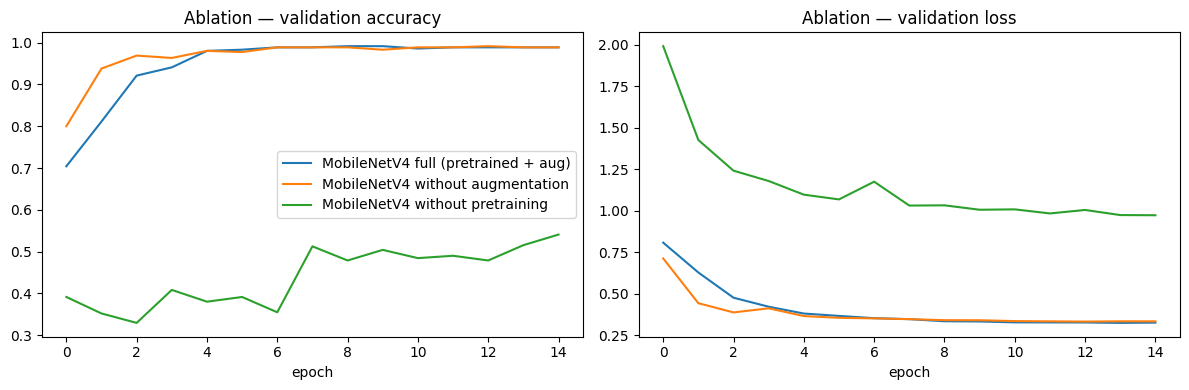

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (_, hist) in ablation_models.items():
    axes[0].plot(hist['val_accuracy'], label=name)
    axes[1].plot(hist['val_loss'], label=name)
axes[0].set_title('Ablation - validation accuracy'); axes[0].set_xlabel('epoch')
axes[1].set_title('Ablation - validation loss'); axes[1].set_xlabel('epoch')
axes[0].legend()
plt.tight_layout(); savefig('curves_ablation.png'); plt.show()

## 8. Explainability: Grad-CAM on MobileNetV4
Grad-CAM weights the feature maps of the last convolutional stage by the gradient of the predicted
class score, showing **which pixels the decision depends on**. For a good model the heat should sit
on the raised fingers, not on the background.

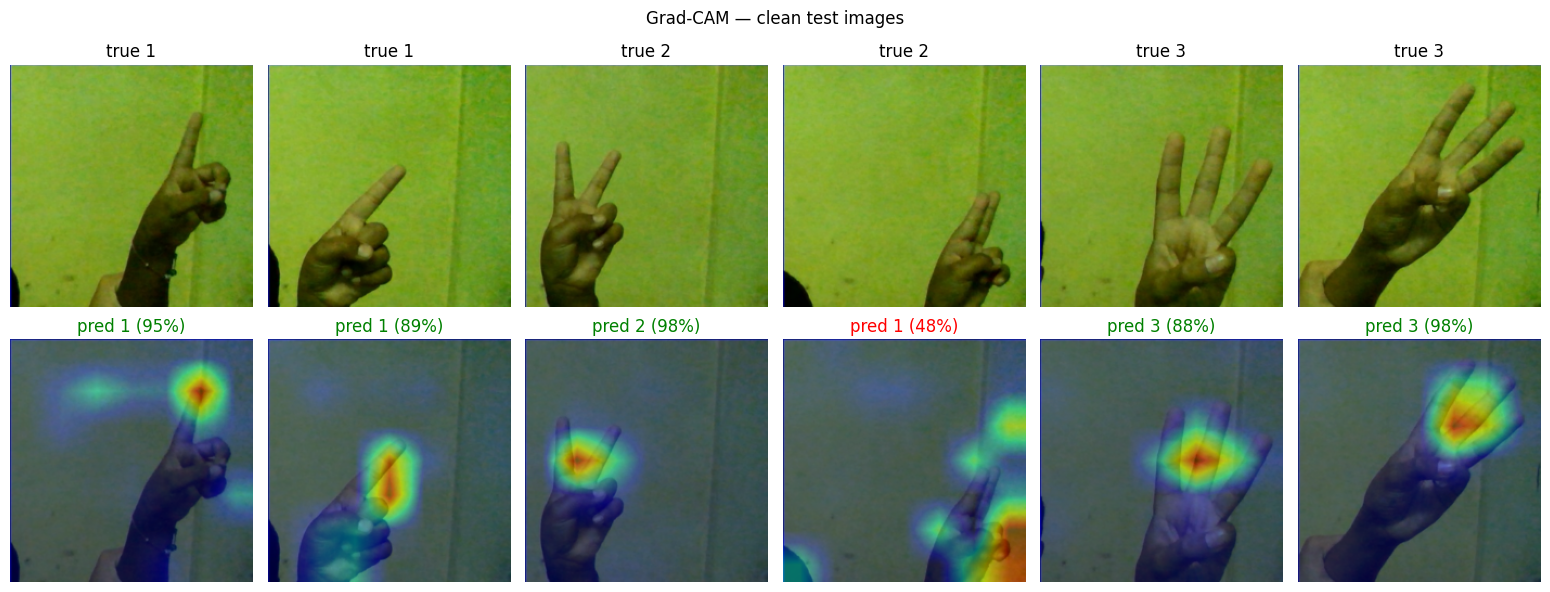

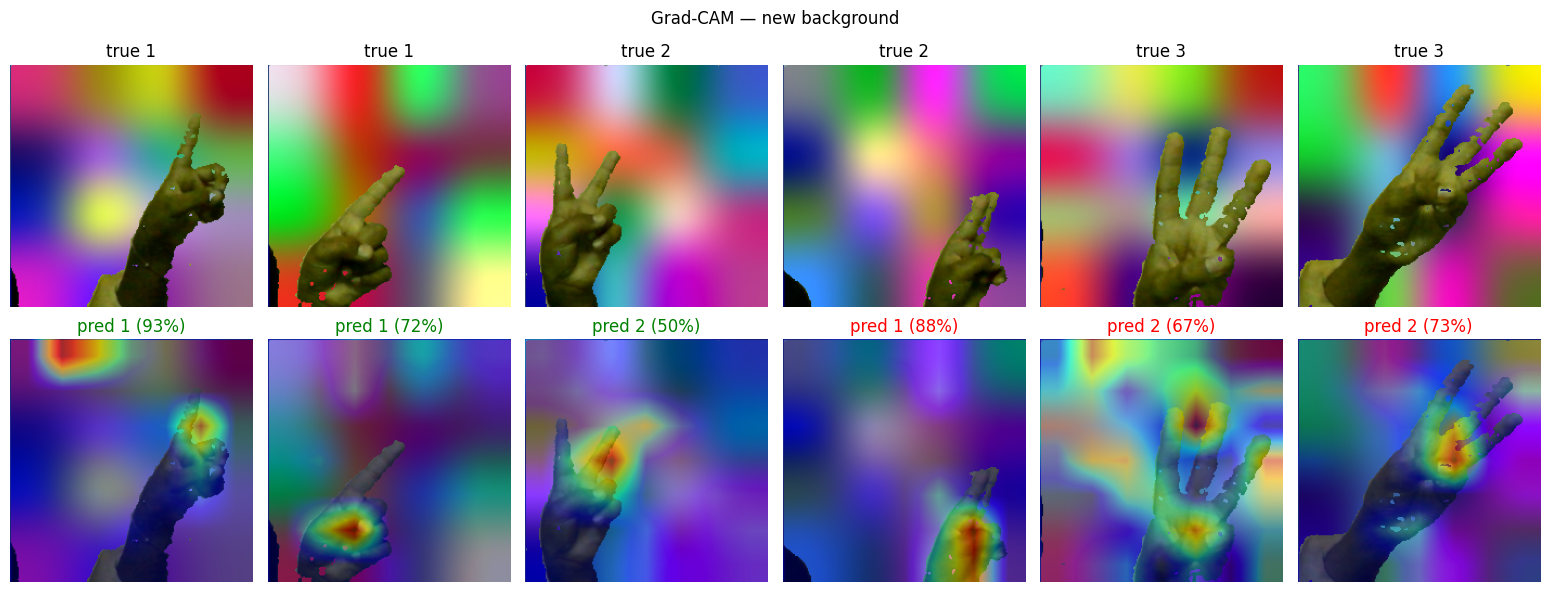

In [22]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        layer.register_forward_hook(self._save)

    def _save(self, module, inputs, output):
        self.activations = output
        if output.requires_grad:  # plain predictions run under no_grad
            output.register_hook(lambda grad: setattr(self, 'gradients', grad))

    def __call__(self, x, class_idx=None):
        self.model.eval()
        logits = self.model(x)
        class_idx = logits.argmax(1).item() if class_idx is None else class_idx
        self.model.zero_grad()
        logits[0, class_idx].backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), F.softmax(logits, 1)[0].detach().cpu().numpy()

gradcam = GradCAM(mnv4_cpu, mnv4_cpu.blocks[-1])

def show_gradcam(pils, labels, title, fname):
    fig, axes = plt.subplots(2, len(pils), figsize=(2.6 * len(pils), 6.2))
    axes = axes.reshape(2, -1)
    for col, (img, label) in enumerate(zip(pils, labels)):
        cam, probs = gradcam(eval_tf(img).unsqueeze(0))
        pred = probs.argmax()
        axes[0, col].imshow(img); axes[0, col].axis('off')
        axes[0, col].set_title(f"true {CLASS_NAMES[label]}")
        axes[1, col].imshow(img); axes[1, col].imshow(cam, cmap='jet', alpha=0.45); axes[1, col].axis('off')
        axes[1, col].set_title(f"pred {CLASS_NAMES[pred]} ({probs[pred]:.0%})",
                               color='green' if pred == label else 'red')
    fig.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

idx = [i for c in range(len(CLASS_NAMES)) for i in np.where(y_test == c)[0][:2]]
show_gradcam([test_pils[i] for i in idx], y_test[idx], 'Grad-CAM - clean test images', 'gradcam_clean.png')
show_gradcam([cond_pils['new background'][i] for i in idx], y_test[idx],
             'Grad-CAM - new background', 'gradcam_new_background.png')

MobileNetV4 misclassified 4 of 295 test images


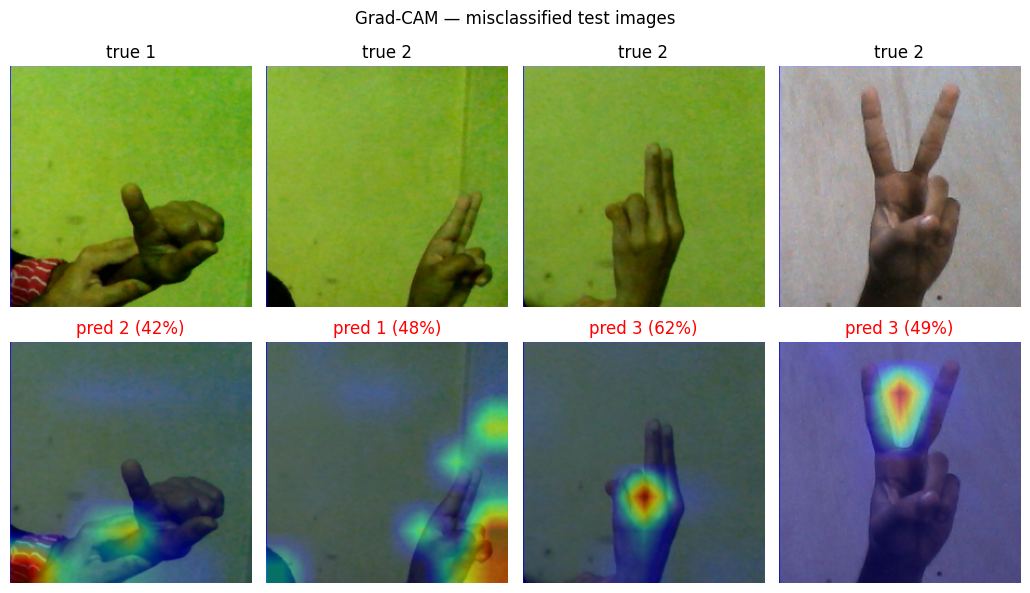

In [23]:
wrong = np.where(test_preds['MobileNetV4 (SOTA)'] != y_test)[0][:6]
print(f"MobileNetV4 misclassified {np.sum(test_preds['MobileNetV4 (SOTA)'] != y_test)} of {len(y_test)} test images")
if len(wrong):
    show_gradcam([test_pils[i] for i in wrong], y_test[wrong], 'Grad-CAM - misclassified test images', 'gradcam_errors.png')

## 9. Export the best model for the web app

In [ ]:
best_name = results.sort_values(['F1 (macro)', 'Accuracy'], ascending=False).iloc[0]['Model']
print("Best model on the test set:", best_name)

export_path = os.path.join(OUT_DIR, 'mobilenetv4_gesture.pt')
torch.save({
    'model_name': MNV4_NAME,
    'state_dict': mnv4_cpu.state_dict(),
    'class_names': CLASS_NAMES,
    'class_labels': CLASS_LABELS,
    'img_size': IMG_SIZE,
    'mean': MEAN,
    'std': STD,
    'test_metrics': results.set_index('Model').loc['MobileNetV4 (SOTA)'].to_dict(),
}, export_path)
print(f"Saved {export_path} ({os.path.getsize(export_path) / 1e6:.1f} MB)")
print("Copy this file into app/ of the repository to run the web app.")

Best model on the test set: MobileNetV4 (SOTA)
Saved /content/drive/MyDrive/asik2/outputs/mobilenetv4_gesture.pt (10.2 MB)
Copy this file into app/ of the repository to run the web app.
